<a href="https://colab.research.google.com/github/chandrahzzz/EDA-COURSE/blob/main/1D%2C2D%2CND.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

23BDS0308
1D,2D,ND


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

In [2]:
# Load the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/catholic.csv"
df = pd.read_csv(url)
print(df.shape)
df.info()

(7430, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7430 entries, 0 to 7429
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  7430 non-null   int64  
 1   id        7430 non-null   int64  
 2   read12    7430 non-null   float64
 3   math12    7430 non-null   float64
 4   female    7430 non-null   int64  
 5   asian     7430 non-null   int64  
 6   hispan    7430 non-null   int64  
 7   black     7430 non-null   int64  
 8   motheduc  7430 non-null   float64
 9   fatheduc  7430 non-null   float64
 10  lfaminc   7430 non-null   float64
 11  hsgrad    5970 non-null   float64
 12  cathhs    7430 non-null   int64  
 13  parcath   7430 non-null   int64  
dtypes: float64(6), int64(8)
memory usage: 812.8 KB


In [3]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
rownames,7430.0,3.715500e+03,2.145001e+03,1.000000,1.858250e+03,3.715500e+03,5.572750e+03,7.430000e+03
id,7430.0,4.589838e+06,2.744467e+06,124902.000000,2.424049e+06,4.592442e+06,7.241106e+06,7.979086e+06
read12,7430.0,5.177240e+01,9.407761e+00,29.150000,4.452500e+01,5.308000e+01,5.947000e+01,6.809000e+01
math12,7430.0,5.213362e+01,9.459117e+00,29.500000,4.502000e+01,5.253000e+01,5.985750e+01,7.137000e+01
female,7430.0,5.173620e-01,4.997321e-01,0.000000,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
asian,7430.0,5.168237e-02,2.213999e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
hispan,7430.0,1.034993e-01,3.046304e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
black,7430.0,7.065949e-02,2.562724e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
motheduc,7430.0,1.335686e+01,2.005982e+00,8.000000,1.200000e+01,1.400000e+01,1.400000e+01,1.800000e+01
fatheduc,7430.0,1.367416e+01,2.267797e+00,8.000000,1.200000e+01,1.400000e+01,1.600000e+01,1.800000e+01


In [4]:
# 1D: Summary statistics of reading score
x = df["read12"]
pd.Series({"Mean": x.mean(), "Median": x.median(), "Minimum": x.min(), "Maximum": x.max(),
           "Range": x.max() - x.min(), "Variance": x.var(), "SD": x.std(),
           "IQR": x.quantile(0.75) - x.quantile(0.25), "Skewness": x.skew(), "Kurtosis": x.kurt()}).round(4)

,0
Mean,51.7724
Median,53.0800
Minimum,29.1500
Maximum,68.0900
Range,38.9400
Variance,88.5060
SD,9.4078
IQR,14.9450
Skewness,-0.3670
Kurtosis,-0.8347


        Count  Proportion
cathhs                   
0        6978      0.9392
1         452      0.0608


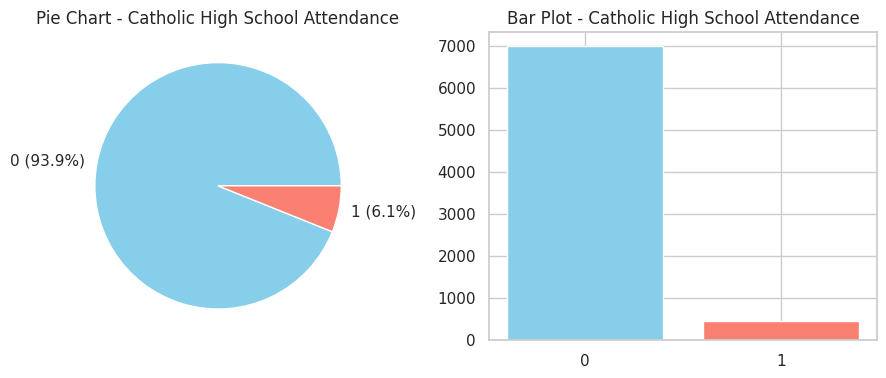

In [5]:
# 1D: Frequency table, pie chart and bar plot of Catholic HS attendance
freq = df["cathhs"].value_counts().sort_index()
print(pd.DataFrame({"Count": freq, "Proportion": (freq / len(df)).round(4)}))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].pie(freq, labels=[f"{i} ({v / len(df):.1%})" for i, v in freq.items()], colors=["skyblue", "salmon"])
ax[0].set_title("Pie Chart - Catholic High School Attendance")
ax[1].bar(freq.index.astype(str), freq, color=["skyblue", "salmon"])
ax[1].set_title("Bar Plot - Catholic High School Attendance")
plt.show()

read12
(20, 25]       0
(25, 30]      21
(30, 35]     357
(35, 40]     684
(40, 45]     888
(45, 50]     989
(50, 55]    1320
(55, 60]    1472
(60, 65]    1303
(65, 70]     396
Name: count, dtype: int64


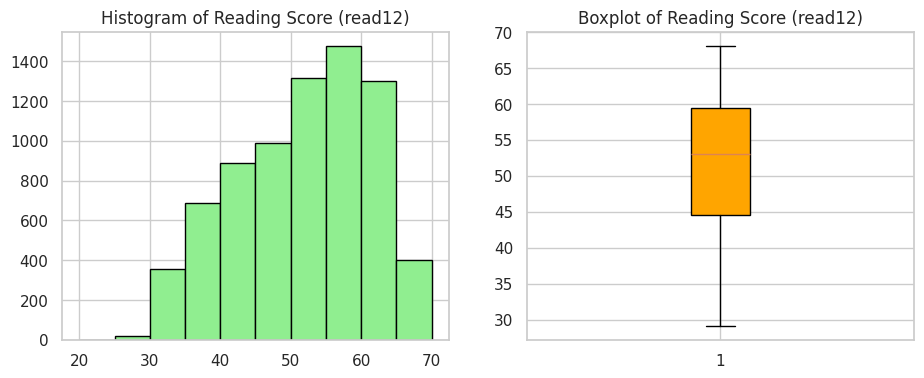

In [6]:
# 1D: Binned frequency, histogram and boxplot of reading score
print(pd.cut(df["read12"], bins=range(20, 75, 5)).value_counts().sort_index())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["read12"], bins=range(20, 75, 5), color="lightgreen", edgecolor="black")
ax[0].set_title("Histogram of Reading Score (read12)")
ax[1].boxplot(df["read12"], patch_artist=True, boxprops=dict(facecolor="orange"))
ax[1].set_title("Boxplot of Reading Score (read12)")
plt.show()

In [7]:
# 2D: Contingency table of gender vs Catholic HS
df["gender"] = df["female"].map({0: "Male", 1: "Female"})
df["cathhs_f"] = df["cathhs"].map({0: "No", 1: "Yes"})
ct = pd.crosstab(df["gender"], df["cathhs_f"]).reindex(["Male", "Female"])
print(ct)
print((pd.crosstab(df["gender"], df["cathhs_f"], normalize="index") * 100).round(2))
print((pd.crosstab(df["gender"], df["cathhs_f"], normalize="columns") * 100).round(2))

cathhs_f    No  Yes
gender             
Male      3341  245
Female    3637  207
cathhs_f     No   Yes
gender               
Female    94.61  5.39
Male      93.17  6.83
cathhs_f     No   Yes
gender               
Female    52.12  45.8
Male      47.88  54.2


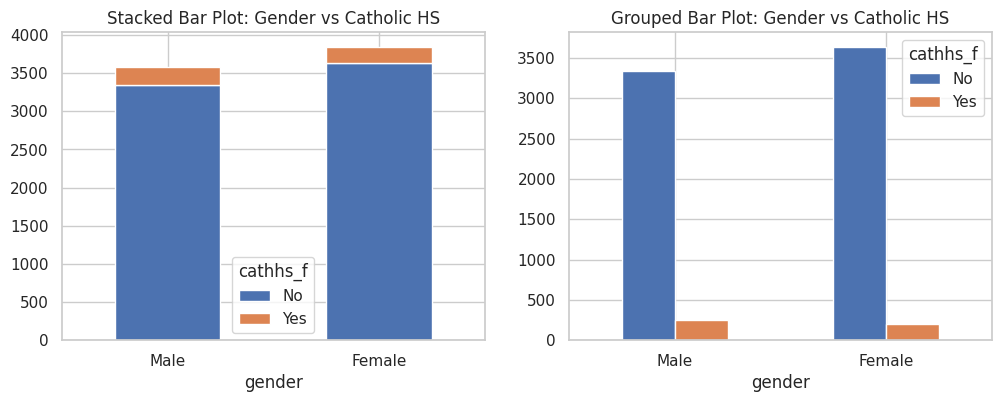

In [8]:
# 2D: Stacked and grouped bar plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ct.plot(kind="bar", stacked=True, ax=ax[0], title="Stacked Bar Plot: Gender vs Catholic HS", rot=0)
ct.plot(kind="bar", ax=ax[1], title="Grouped Bar Plot: Gender vs Catholic HS", rot=0)
plt.show()

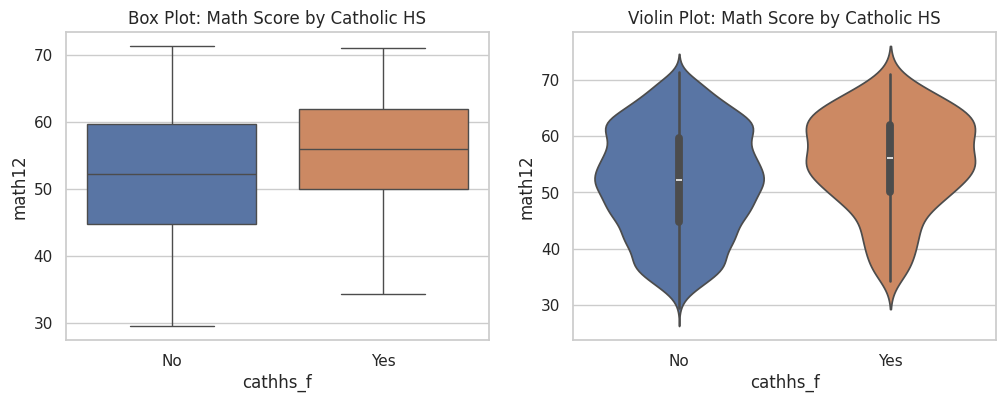

In [9]:
# 2D: Box plot and violin plot of math score by Catholic HS
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="cathhs_f", y="math12", hue="cathhs_f", legend=False, ax=ax[0])
sns.violinplot(data=df, x="cathhs_f", y="math12", hue="cathhs_f", legend=False, ax=ax[1])
ax[0].set_title("Box Plot: Math Score by Catholic HS")
ax[1].set_title("Violin Plot: Math Score by Catholic HS")
plt.show()

Pearson : 0.7104133663371397
Spearman: 0.7096083282039561


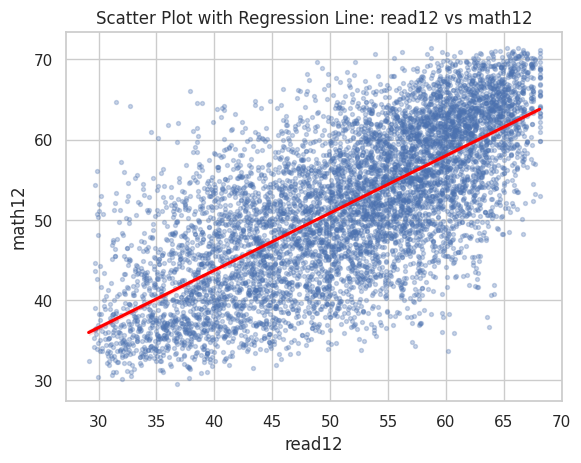

In [10]:
# 2D: Pearson and Spearman correlation with regression line
print("Pearson :", df["read12"].corr(df["math12"], method="pearson"))
print("Spearman:", df["read12"].corr(df["math12"], method="spearman"))
sns.regplot(data=df, x="read12", y="math12", scatter_kws={"alpha": 0.3, "s": 8}, line_kws={"color": "red"})
plt.title("Scatter Plot with Regression Line: read12 vs math12")
plt.show()

                  Mean    SD
gender cathhs_f             
Female No        51.23  9.31
       Yes       54.29  8.43
Male   No        52.68  9.60
       Yes       56.31  8.44


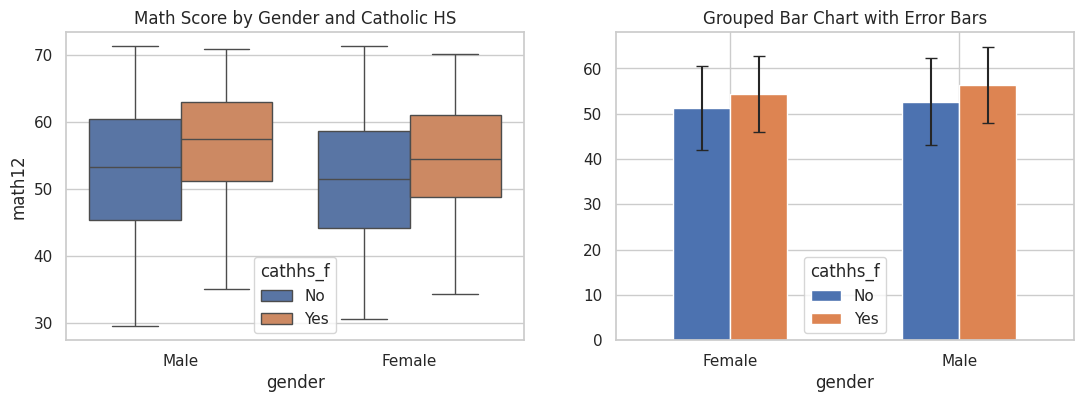

In [11]:
# ND: Math score by gender and Catholic HS
summ = df.groupby(["gender", "cathhs_f"])["math12"].agg(Mean="mean", SD="std").round(2)
print(summ)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="gender", y="math12", hue="cathhs_f", ax=ax[0])
summ["Mean"].unstack().plot(kind="bar", yerr=summ["SD"].unstack(), capsize=4, ax=ax[1], rot=0)
ax[0].set_title("Math Score by Gender and Catholic HS")
ax[1].set_title("Grouped Bar Chart with Error Bars")
plt.show()

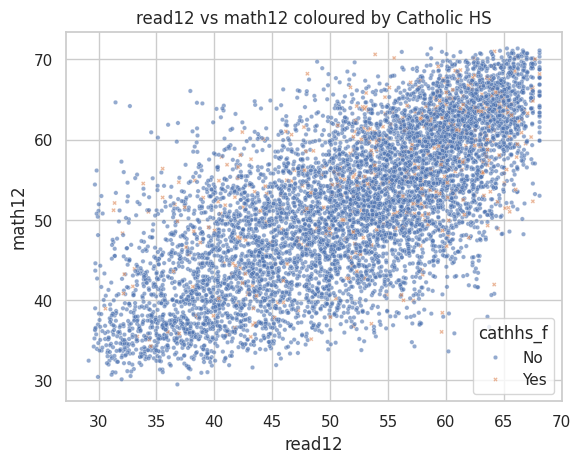

,0
cathhs_f,
No,0.713706
Yes,0.616285


In [12]:
# ND: Scatter coloured by Catholic HS and correlation per group
sns.scatterplot(data=df, x="read12", y="math12", hue="cathhs_f", style="cathhs_f", alpha=0.6, s=10)
plt.title("read12 vs math12 coloured by Catholic HS")
plt.show()
df.groupby("cathhs_f")[["read12", "math12"]].apply(lambda g: g["read12"].corr(g["math12"]))

          read12  math12  motheduc  fatheduc  lfaminc
read12     1.000   0.710     0.285     0.317    0.259
math12     0.710   1.000     0.342     0.375    0.316
motheduc   0.285   0.342     1.000     0.583    0.405
fatheduc   0.317   0.375     0.583     1.000    0.446
lfaminc    0.259   0.316     0.405     0.446    1.000


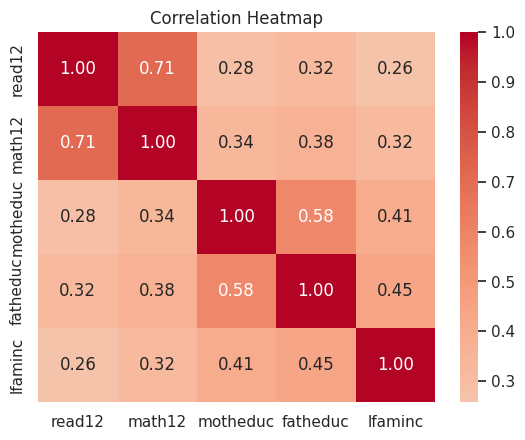

In [13]:
# ND: Correlation matrix and heatmap
num = df[["read12", "math12", "motheduc", "fatheduc", "lfaminc"]]
print(num.corr().round(3))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

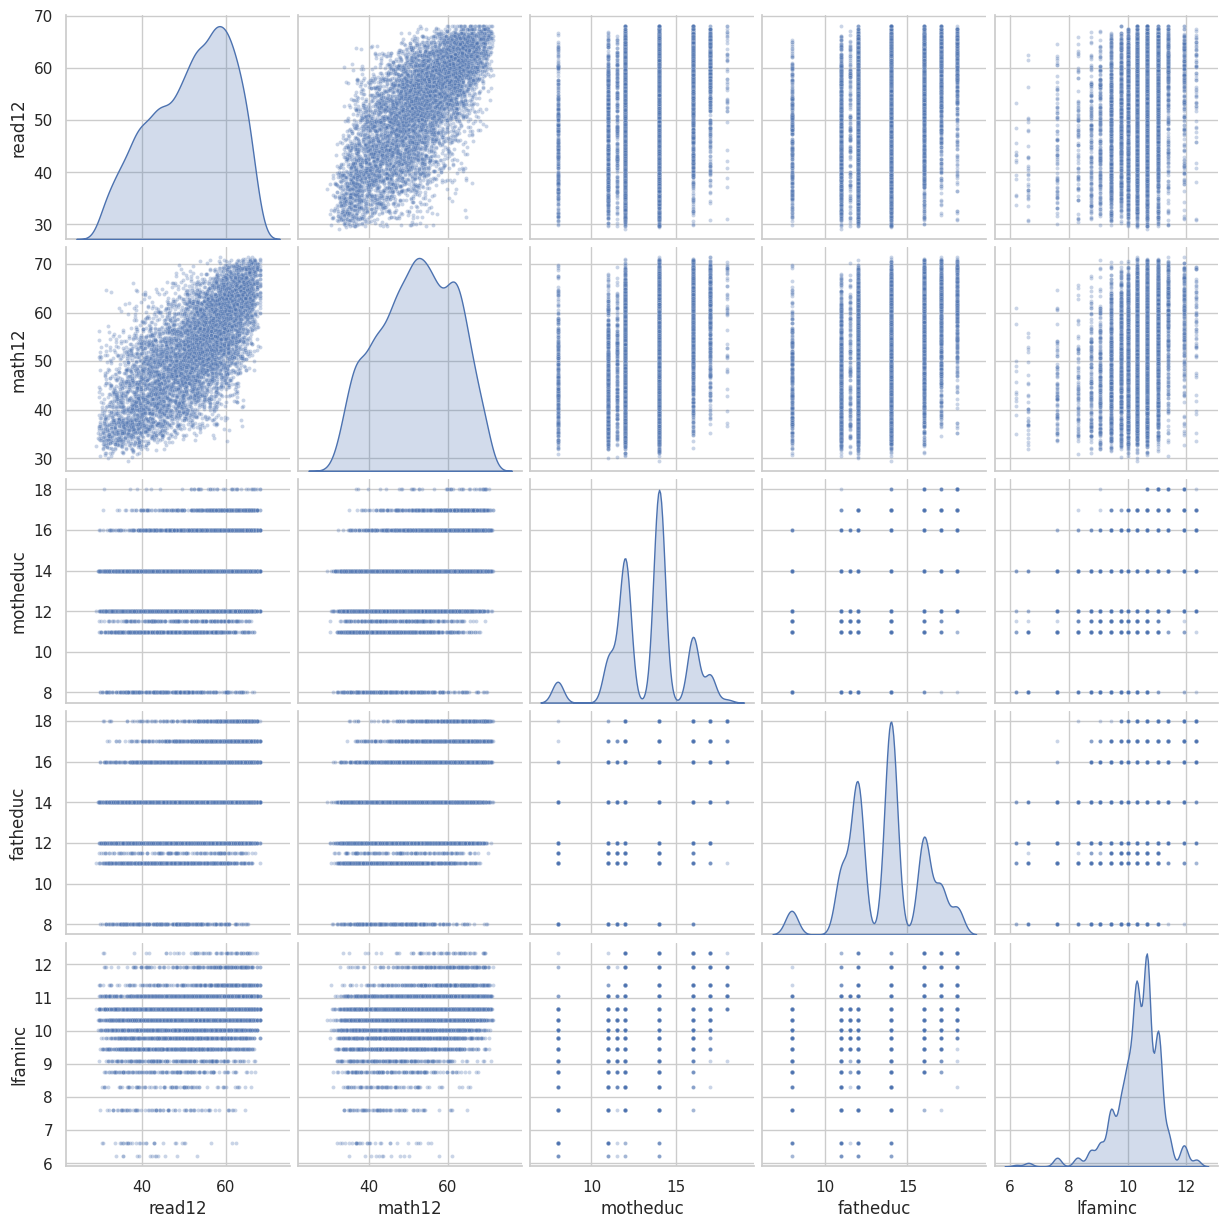

In [14]:
# ND: Pairs plot of numerical features
sns.pairplot(num, diag_kind="kde", plot_kws={"alpha": 0.3, "s": 8})
plt.show()